# 05 - YOLOv8 Brain Tumor Detection

Trains an object detection model using **YOLOv8** (Ultralytics) to accurately detect and localize brain tumors in MRI scans with bounding boxes.

### Workflow Overview:
1. **Dependencies & Setup**: Install and import Ultralytics YOLOv8, PyTorch, and MLflow.
2. **MLflow Setup**: Connect to remote tracking server to record training runs and metrics.
3. **Data Configuration**: Auto-detect dataset path (Kaggle or Local) and construct verified `data.yaml`.
4. **Dataset Verification**: Inspect sample MRI images with ground-truth bounding box labels.
5. **Model Initialization**: Load pre-trained `yolov8n.pt` (Nano model) for transfer learning.
6. **Model Training**: Train for 30 epochs with early stopping (`patience=10`) and real-time augmentations.
7. **Test Evaluation**: Evaluate detection performance on the unseen test set (mAP@0.5, mAP@0.5:0.95, Precision, Recall).
8. **Visualization**: Display training loss curves, mAP progression, and prediction results.
9. **Model Export**: Save `best.pt` to `models/detection/`.
10. **MLflow Logging**: Log all parameters, final test metrics, and plot artifacts to MLflow.

In [2]:
%pip install "cryptography>=49,<51"

Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install --no-cache-dir ultralytics==8.4.192

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Install dependencies (silent)
!pip install -q mlflow==3.14.0

import os
import sys
import json
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

import torch
from ultralytics import YOLO

print(f"Python Version:      {sys.version.split()[0]}")
print(f"PyTorch Version:     {torch.__version__}")
print(f"CUDA Available:      {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name:         {torch.cuda.get_device_name(0)}")
    device = 0
else:
    print("Running on CPU (GPU recommended on Kaggle!)")
    device = "cpu"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python Version:      3.13.15
PyTorch Version:     2.11.0+cu128
CUDA Available:      True
Device Name:         Tesla T4


In [4]:
# MLflow Setup — connects to remote tracking server
import mlflow

# Read credentials from Kaggle Secrets (Add-ons > Secrets)
try:
    from kaggle_secrets import UserSecretsClient
    s = UserSecretsClient()
    os.environ["MLFLOW_TRACKING_URI"]      = s.get_secret("MLFLOW_TRACKING_URI")
    os.environ["MLFLOW_TRACKING_USERNAME"] = s.get_secret("MLFLOW_TRACKING_USERNAME")
    os.environ["MLFLOW_TRACKING_PASSWORD"] = s.get_secret("MLFLOW_TRACKING_PASSWORD")
    print("Loaded MLflow credentials from Kaggle Secrets.")
except Exception:
    # Fallback credentials
    os.environ["MLFLOW_TRACKING_URI"]      = "https://dangerous-tackle-thoroughly-weight.trycloudflare.com "
    os.environ["MLFLOW_TRACKING_USERNAME"] = "kaggle"
    os.environ["MLFLOW_TRACKING_PASSWORD"] = "tS42TaFnk5hDOGM9i6RmeXQI"
    print("ℹ Using hardcoded MLflow credentials (fallback).")

mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
mlflow.set_experiment("neurovision-yolov8")
print(f"MLflow Tracking URI: {mlflow.get_tracking_uri()}")

Loaded MLflow credentials from Kaggle Secrets.
MLflow Tracking URI: https://picks-reasonable-composed-cadillac.trycloudflare.com


In [5]:
# Setup Paths & Auto-generate verified data.yaml
if Path("/kaggle/input").exists():
    WORK_DIR = Path("/kaggle/working")
    # Search for prepared detection dataset in Kaggle inputs
    candidates = list(Path("/kaggle/input").rglob("images"))
    if candidates:
        # Choose the parent of 'images' directory
        DATA_DIR = candidates[0].parent
    else:
        DATA_DIR = Path("/kaggle/input/neurovision-detection")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_DIR = ROOT / "data" / "prepared" / "detection"
    WORK_DIR = ROOT

MODEL_DIR = WORK_DIR / "models" / "detection"
OUT_DIR = WORK_DIR / "outputs"
METRICS_DIR = OUT_DIR / "metrics"
REPORTS_DIR = OUT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data Directory:      {DATA_DIR}")
print(f"Working Directory:   {WORK_DIR}")
print(f"Model Directory:     {MODEL_DIR}")

# Generate verified data.yaml with absolute paths for Ultralytics
data_yaml_path = WORK_DIR / "data.yaml"
train_images = DATA_DIR / "images" / "train"
val_images   = DATA_DIR / "images" / "valid"
test_images  = DATA_DIR / "images" / "test"

# Fallback if valid is named val
if not val_images.exists() and (DATA_DIR / "images" / "val").exists():
    val_images = DATA_DIR / "images" / "val"

yaml_content = f"""# YOLOv8 Brain Tumor Detection Dataset
path: {DATA_DIR.resolve().as_posix()}
train: {train_images.resolve().as_posix()}
val: {val_images.resolve().as_posix()}
test: {test_images.resolve().as_posix()}

nc: 1
names: ['tumor']
"""

data_yaml_path.write_text(yaml_content, encoding="utf-8")
print(f"\nGenerated data.yaml at: {data_yaml_path}")
print(yaml_content)

Data Directory:      /kaggle/input/datasets/hamzalafsioui/neurovision-detection/detection
Working Directory:   /kaggle/working
Model Directory:     /kaggle/working/models/detection

Generated data.yaml at: /kaggle/working/data.yaml
# YOLOv8 Brain Tumor Detection Dataset
path: /kaggle/input/datasets/hamzalafsioui/neurovision-detection/detection
train: /kaggle/input/datasets/hamzalafsioui/neurovision-detection/detection/images/train
val: /kaggle/input/datasets/hamzalafsioui/neurovision-detection/detection/images/valid
test: /kaggle/input/datasets/hamzalafsioui/neurovision-detection/detection/images/test

nc: 1
names: ['tumor']



Training images:   3672
Validation images: 787
Test images:       788


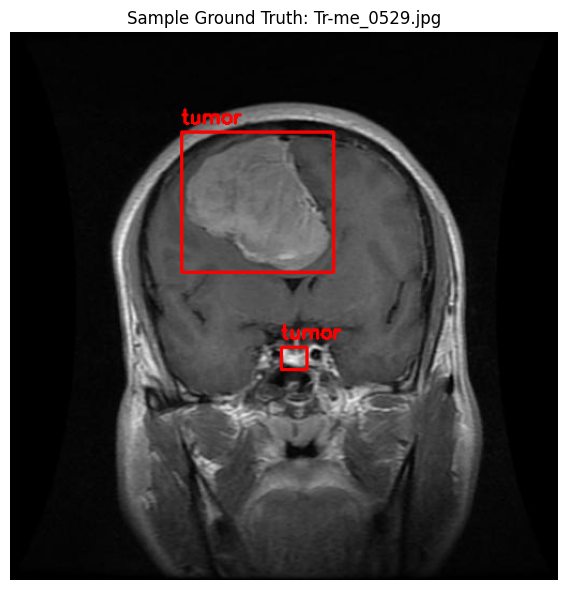

In [6]:
# Verify dataset count and visualize a sample training image with bounding box
train_imgs = list(train_images.glob("*.jpg")) + list(train_images.glob("*.png"))
val_imgs   = list(val_images.glob("*.jpg")) + list(val_images.glob("*.png"))
test_imgs  = list(test_images.glob("*.jpg")) + list(test_images.glob("*.png"))

print(f"Training images:   {len(train_imgs)}")
print(f"Validation images: {len(val_imgs)}")
print(f"Test images:       {len(test_imgs)}")

if train_imgs:
    sample_img_path = train_imgs[0]
    sample_lbl_path = DATA_DIR / "labels" / "train" / f"{sample_img_path.stem}.txt"
    
    img = cv2.imread(str(sample_img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    
    if sample_lbl_path.exists():
        with open(sample_lbl_path, "r") as f:
            lines = f.readlines()
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls, x_c, y_c, bw, bh = map(float, parts)
                # Convert normalized YOLO coordinates to pixel boxes
                x1 = int((x_c - bw / 2) * w)
                y1 = int((y_c - bh / 2) * h)
                x2 = int((x_c + bw / 2) * w)
                y2 = int((y_c + bh / 2) * h)
                cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(img_rgb, "tumor", (x1, max(y1 - 8, 15)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    
    plt.figure(figsize=(6, 6))
    plt.imshow(img_rgb)
    plt.title(f"Sample Ground Truth: {sample_img_path.name}", fontsize=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Warning: No training images found. Please verify the dataset path!")

In [9]:
%pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.2 MB/s  0:00:00
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.2.0
    Uninstalling ultralytics-8.2.0:
      Successfully uninstalled ultralytics-8.2.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]
Note: you may need to restart the kernel to use updated packages.


In [7]:

# Set this BEFORE importing torch or ultralytics
import os
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

import torch
import ultralytics
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

# Use only the official, trusted Ultralytics checkpoint
model = YOLO("yolov8n.pt")

print("Loaded YOLOv8n successfully!")
print("Task:", model.task)


PyTorch: 2.11.0+cu128
Ultralytics: 8.4.192
Loaded YOLOv8n successfully!
Task: detect


In [8]:
# Load pre-trained YOLOv8 Nano model for transfer learning
model = YOLO("yolov8n.pt")

print("Loaded YOLOv8n (pre-trained on COCO)")
print(f"Model Architecture: {model.task}")

Loaded YOLOv8n (pre-trained on COCO)
Model Architecture: detect


In [9]:
# Train YOLOv8 on Brain Tumor MRI Dataset
EPOCHS = 30
BATCH_SIZE = 16
IMG_SIZE = 640

results = model.train(
    data=str(data_yaml_path),
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMG_SIZE,
    patience=10,                # Early stopping if no improvement for 10 epochs
    device=device,
    project=str(WORK_DIR / "runs" / "detect"),
    name="tumor_yolov8",
    exist_ok=True,
    save=True,
    plots=True,
    verbose=True
)

print("\nYOLOv8 Training Completed!")

New https://pypi.org/project/ultralytics/8.4.193 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.9

2026/10/30 09:44:32 WARNING mlflow.spark: With Pyspark >= 3.2, PYSPARK_PIN_THREAD environment variable must be set to false for Spark datasource autologging to work.
2026/10/30 09:44:32 INFO mlflow.tracking.fluent: Autologging successfully enabled for pyspark.


MLflow: logging run_id(80e4303c474747aca7f2378ccee5b2d6) to https://picks-reasonable-composed-cadillac.trycloudflare.com
MLflow: disable with 'yolo settings mlflow=False'
Using 3672 train, 787 val images for fraction=1.0 at imgsz=640
Using 2 dataloader workers
Logging results to /kaggle/working/runs/detect/tumor_yolov8
Starting training for 30 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/30      1.97G      1.079      1.667      1.252         24        640: 100% ━━━━━━━━━━━━ 230/230 7.4it/s 31.0s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 5.1it/s 4.9s0.2s
                   all        787        889      0.802       0.56      0.696      0.499

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/30      2.52G      1.252      1.261      1.298         29        640: 0% ──────────── 0/230  0.1s

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      2.52G       1.14        1.1       1.29         13        640: 100% ━━━━━━━━━━━━ 230/230 8.4it/s 27.3s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 6.1it/s 4.1s0.2s
                   all        787        889       0.82        0.7        0.8      0.549

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.52G      1.121      1.053      1.281         15        640: 100% ━━━━━━━━━━━━ 230/230 8.1it/s 28.2s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 6.0it/s 4.1s0.2s
                   all        787        889      0.786      0.692       0.77      0.527

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      2.52G      1.087      0.961       1.25         12        640: 100% ━━━━━━━━━━━━ 230/230 8.4it/s 27.4s0.2ss
                 Class     Ima

In [10]:
# Evaluate on the Unseen Test Set using best weights
best_weights = WORK_DIR / "runs" / "detect" / "tumor_yolov8" / "weights" / "best.pt"
if not best_weights.exists():
    # Fallback check
    candidates = list((WORK_DIR / "runs").rglob("best.pt"))
    if candidates:
        best_weights = candidates[0]

print(f"Evaluating best checkpoint: {best_weights}")
best_model = YOLO(str(best_weights))

# Run validation on test split
test_metrics = best_model.val(
    data=str(data_yaml_path),
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=device
)

map50    = float(test_metrics.box.map50)
map50_95 = float(test_metrics.box.map)
prec     = float(test_metrics.box.mp)
rec      = float(test_metrics.box.mr)
f1       = float(2 * (prec * rec) / (prec + rec + 1e-8))

print("=" * 45)
print("       YOLOv8 TEST SET EVALUATION")
print("=" * 45)
print(f"Precision:          {prec:.4f} ({prec * 100:.2f}%)")
print(f"Recall:             {rec:.4f} ({rec * 100:.2f}%)")
print(f"F1-Score:           {f1:.4f} ({f1 * 100:.2f}%)")
print(f"mAP@0.5:            {map50:.4f} ({map50 * 100:.2f}%)")
print(f"mAP@0.5:0.95:       {map50_95:.4f} ({map50_95 * 100:.2f}%)")
print("=" * 45)

# Save test metrics JSON
metrics_dict = {
    "model": "YOLOv8n",
    "precision": round(prec, 4),
    "recall": round(rec, 4),
    "f1_score": round(f1, 4),
    "mAP_50": round(map50, 4),
    "mAP_50_95": round(map50_95, 4),
    "epochs_trained": EPOCHS,
    "img_size": IMG_SIZE
}

test_metrics_file = METRICS_DIR / "yolo_test_metrics.json"
with open(test_metrics_file, "w", encoding="utf-8") as f:
    json.dump(metrics_dict, f, indent=4)
print(f"Saved metrics to {test_metrics_file}")

Evaluating best checkpoint: /kaggle/working/runs/detect/tumor_yolov8/weights/best.pt
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 6.1±4.4 MB/s, size: 23.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/hamzalafsioui/neurovision-detection/detection/labels/test... 788 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 788/788 396.1it/s 2.0s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/hamzalafsioui/neurovision-detection/detection/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 7.0it/s 7.1s0.1s
                   all        788        869      0.937      0.

Copied training curves to /kaggle/working/outputs/reports/yolo_training_curves.png


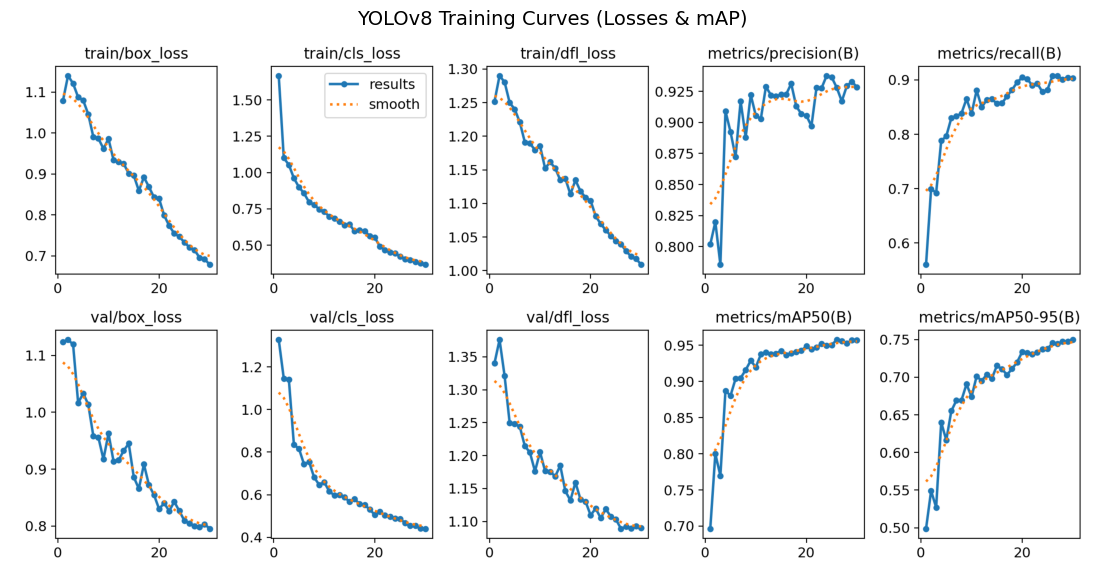

Copied confusion matrix to /kaggle/working/outputs/metrics/yolo_confusion_matrix.png


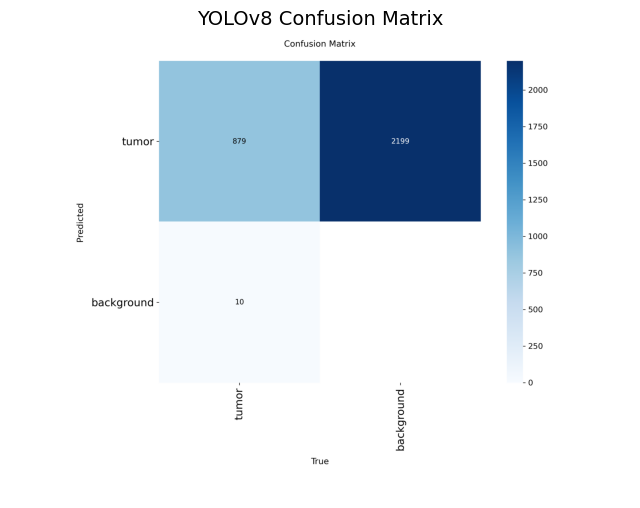

In [11]:
# Copy and display training curves and confusion matrix
run_dir = WORK_DIR / "runs" / "detect" / "tumor_yolov8"

curve_src = run_dir / "results.png"
cm_src    = run_dir / "confusion_matrix.png"

if curve_src.exists():
    shutil.copy(curve_src, REPORTS_DIR / "yolo_training_curves.png")
    print(f"Copied training curves to {REPORTS_DIR / 'yolo_training_curves.png'}")
    plt.figure(figsize=(14, 8))
    plt.imshow(Image.open(curve_src))
    plt.title("YOLOv8 Training Curves (Losses & mAP)", fontsize=14)
    plt.axis("off")
    plt.show()

if cm_src.exists():
    shutil.copy(cm_src, METRICS_DIR / "yolo_confusion_matrix.png")
    print(f"Copied confusion matrix to {METRICS_DIR / 'yolo_confusion_matrix.png'}")
    plt.figure(figsize=(8, 8))
    plt.imshow(Image.open(cm_src))
    plt.title("YOLOv8 Confusion Matrix", fontsize=14)
    plt.axis("off")
    plt.show()

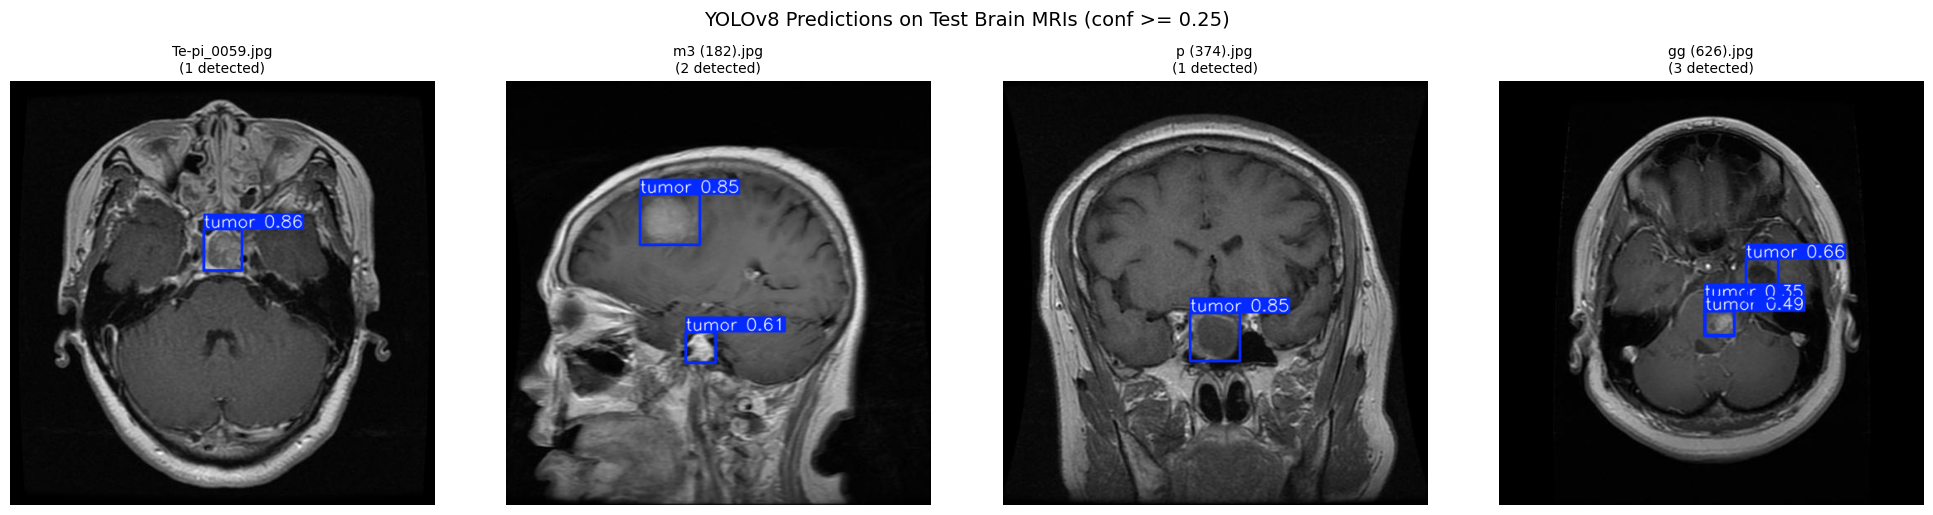

Saved prediction visualization to /kaggle/working/outputs/reports/yolo_sample_predictions.png


In [12]:
# Run visual inference on 4 test images and plot predictions
sample_test_imgs = test_imgs[:4] if len(test_imgs) >= 4 else test_imgs

if sample_test_imgs:
    fig, axes = plt.subplots(1, len(sample_test_imgs), figsize=(5 * len(sample_test_imgs), 5))
    if len(sample_test_imgs) == 1:
        axes = [axes]
    
    for ax, img_p in zip(axes, sample_test_imgs):
        preds = best_model.predict(source=str(img_p), conf=0.25, imgsz=IMG_SIZE, verbose=False)
        plotted_img = preds[0].plot()  # BGR plotted with boxes & labels
        plotted_rgb = cv2.cvtColor(plotted_img, cv2.COLOR_BGR2RGB)
        
        ax.imshow(plotted_rgb)
        ax.set_title(f"{img_p.name}\n({len(preds[0].boxes)} detected)", fontsize=10)
        ax.axis("off")
    
    plt.suptitle("YOLOv8 Predictions on Test Brain MRIs (conf >= 0.25)", fontsize=14, y=1.02)
    plt.tight_layout()
    
    pred_fig_path = REPORTS_DIR / "yolo_sample_predictions.png"
    plt.savefig(pred_fig_path, bbox_inches="tight", dpi=150)
    plt.show()
    print(f"Saved prediction visualization to {pred_fig_path}")

In [13]:
# Export and save best model weights to models/detection/
dest_best_yolo = MODEL_DIR / "best_yolov8.pt"
dest_best_pt   = MODEL_DIR / "best.pt"

shutil.copy(best_weights, dest_best_yolo)
shutil.copy(best_weights, dest_best_pt)

print(f"Saved model to: {dest_best_yolo} ({dest_best_yolo.stat().st_size / 1e6:.2f} MB)")
print(f"Saved alias to: {dest_best_pt}")

# Save class names info
class_info = {"classes": ["tumor"], "num_classes": 1}
with open(MODEL_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_info, f, indent=4)
print(f"Saved class info to: {MODEL_DIR / 'class_names.json'}")

Saved model to: /kaggle/working/models/detection/best_yolov8.pt (6.49 MB)
Saved alias to: /kaggle/working/models/detection/best.pt
Saved class info to: /kaggle/working/models/detection/class_names.json


In [14]:
# Log Run to MLflow
try:
    with mlflow.start_run(run_name="yolov8-tumor-detection"):
        # Log Hyperparameters
        mlflow.log_params({
            "model_type": "YOLOv8n",
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "image_size": IMG_SIZE,
            "early_stopping_patience": 10,
            "device": str(device)
        })
        
        # Log Evaluation Metrics
        mlflow.log_metrics({
            "test_precision": prec,
            "test_recall": rec,
            "test_f1": f1,
            "test_mAP50": map50,
            "test_mAP50_95": map50_95
        })
        
        # Log Artifacts
        if (METRICS_DIR / "yolo_test_metrics.json").exists():
            mlflow.log_artifact(str(METRICS_DIR / "yolo_test_metrics.json"))
        if (REPORTS_DIR / "yolo_training_curves.png").exists():
            mlflow.log_artifact(str(REPORTS_DIR / "yolo_training_curves.png"))
        if (METRICS_DIR / "yolo_confusion_matrix.png").exists():
            mlflow.log_artifact(str(METRICS_DIR / "yolo_confusion_matrix.png"))
        if (REPORTS_DIR / "yolo_sample_predictions.png").exists():
            mlflow.log_artifact(str(REPORTS_DIR / "yolo_sample_predictions.png"))
        if dest_best_yolo.exists():
            mlflow.log_artifact(str(dest_best_yolo))
            
        print("Successfully logged metrics, parameters, and artifacts to MLflow!")
        print(f"View run at: {os.environ.get('MLFLOW_TRACKING_URI')}")
except Exception as e:
    print(f"MLflow logging error: {e}")
    print("Training and local evaluation were successful.")

Successfully logged metrics, parameters, and artifacts to MLflow!
View run at: https://picks-reasonable-composed-cadillac.trycloudflare.com
🏃 View run yolov8-tumor-detection at: https://picks-reasonable-composed-cadillac.trycloudflare.com/#/experiments/4/runs/3998faf8418641ada1cd397520915479
🧪 View experiment at: https://picks-reasonable-composed-cadillac.trycloudflare.com/#/experiments/4


In [15]:
import os
from IPython.display import FileLink, display

# Paths provided
files = [
    '/kaggle/working/models/detection/best.pt',
    '/kaggle/working/models/detection/best_yolov8.pt',
    '/kaggle/working/models/detection/class_names.json'
]

# Generate relative links for Kaggle's display engine
for file_path in files:
    if os.path.exists(file_path):
        rel_path = os.path.relpath(file_path, '/kaggle/working')
        print(f"Download {os.path.basename(file_path)}:")
        display(FileLink(rel_path))
    else:
        print(f"File not found on disk: {file_path}")

Download best.pt:


/kaggle/working/models/detection/best.pt

Download best_yolov8.pt:


/kaggle/working/models/detection/best_yolov8.pt

Download class_names.json:


/kaggle/working/models/detection/class_names.json